# ATR-FTIR *Pinus pinaster* / *Fusarium circinatum*: PCA on raw and second-derivative spectra

Overlay plots and PCA of the ATR-FTIR spectra at each timepoint (T0–T7), using the raw absorbance and its Savitzky-Golay second derivative.

The second derivative is computed on the full spectrum and the regions are cut afterwards. There is a gap of about 1000 cm⁻¹ between 1800 and 2800 cm⁻¹ with no measured points. If the derivative were computed on a table that already had the gap removed, the last fingerprint point and the first stretching point would be treated as neighbours and the result would show an artificial jump.

Three regions are then built with `build_region_subset`: Combined (800–1800 and 2800–3800 cm⁻¹), Fingerprint (800–1800 cm⁻¹) and Stretching (2800–3800 cm⁻¹). The Combined table, with `absorbance_raw` and `second_derivative_raw`, is saved to `Outputs/Spectra_Data/Full_data_infection_status_per_timepoint.csv`.

The overlay plots show the raw spectra over the full range and the second derivative in the Combined region. PCA is run per timepoint for each region, on raw and second-derivative values, and then again on three groups of timepoints.

## Imports and paths

Libraries, paths, plotting defaults and the constants used further down: `N_BOOTSTRAP` and `RANDOM_STATE` for the bootstrap, `OVERLAP_THRESHOLD` for the Bhattacharyya flag, `ALPHA` for the significance level, and the two wavenumber windows.

In [1]:
%%time
%matplotlib inline
import math
import os

import matplotlib.pyplot as plt
import matplotlib.transforms as transforms
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.patches import Ellipse, Patch
from scipy.signal import savgol_filter
from scipy.stats import chi2, rankdata
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial Unicode MS', 'DejaVu Sans', 'Liberation Sans', 'Helvetica']

BASE_DIR = r'C:/Users/MCL/Desktop/ML_ATR_FTIR_Spectra_Ppinaster'
DATA_FILE = os.path.join(BASE_DIR, 'Outputs', 'Spectra_Data', 'Full_data_infection_status.csv')
OUTPUT_DIR = os.path.join(BASE_DIR, 'Outputs', 'Plots', '1_PCA_Combined_Regions_Raw_2Derivative_Per_Timepoint')
os.makedirs(OUTPUT_DIR, exist_ok=True)

N_BOOTSTRAP = 2000
RANDOM_STATE = 42
OVERLAP_THRESHOLD = 0.5
ALPHA = 0.05

FINGERPRINT = (800, 1800)
STRETCHING = (2800, 3800)

CPU times: total: 3.22 s
Wall time: 6.51 s


## Load data

Raw absorbance for every sample, timepoint and wavenumber, over the whole measured range.

In [2]:
%%time
df = pd.read_csv(DATA_FILE)
df

CPU times: total: 6.08 s
Wall time: 6.54 s


,wavenumber,absorbance,sample_name,infection_status,trial,status,timepoint,sample_num,replicate
0,3996.67,0.009109,Pp_E1_T0_CT_01_1,CONTROL,E1,CT,T0,1,1
1,3994.61,0.009036,Pp_E1_T0_CT_01_1,CONTROL,E1,CT,T0,1,1
2,3992.55,0.008813,Pp_E1_T0_CT_01_1,CONTROL,E1,CT,T0,1,1
3,3990.50,0.008795,Pp_E1_T0_CT_01_1,CONTROL,E1,CT,T0,1,1
4,3988.44,0.008893,Pp_E1_T0_CT_01_1,CONTROL,E1,CT,T0,1,1
...,...,...,...,...,...,...,...,...,...
5338387,407.70,0.438713,Pp_E3_T7_FC_30_2,FUSARIUM,E3,FC,T7,30,2
5338388,405.64,0.441002,Pp_E3_T7_FC_30_2,FUSARIUM,E3,FC,T7,30,2
5338389,403.58,0.438678,Pp_E3_T7_FC_30_2,FUSARIUM,E3,FC,T7,30,2
5338390,401.52,0.436239,Pp_E3_T7_FC_30_2,FUSARIUM,E3,FC,T7,30,2


## Points per sample

Every sample should have the same number of wavenumber points. This is checked before any region cut or transformation.

In [3]:
%%time
counts_per_sample = df.groupby('sample_name')['wavenumber'].count()
print(counts_per_sample)

sample_name
Pp_E1_T0_CT_01_1    1748
Pp_E1_T0_CT_01_2    1748
Pp_E1_T0_CT_02_1    1748
Pp_E1_T0_CT_02_2    1748
Pp_E1_T0_CT_03_1    1748
                    ... 
Pp_E3_T7_FC_28_2    1748
Pp_E3_T7_FC_29_1    1748
Pp_E3_T7_FC_29_2    1748
Pp_E3_T7_FC_30_1    1748
Pp_E3_T7_FC_30_2    1748
Name: wavenumber, Length: 3054, dtype: int64
CPU times: total: 500 ms
Wall time: 520 ms


## Unique wavenumbers

Number of distinct wavenumbers and the first 20 values.

In [4]:
%%time
unique_wavenumbers = df['wavenumber'].unique()
print(f"Number of unique wavenumbers: {len(unique_wavenumbers)}")
print("First 20 unique wavenumbers:", unique_wavenumbers[:20])

Number of unique wavenumbers: 1748
First 20 unique wavenumbers: [3996.67 3994.61 3992.55 3990.5  3988.44 3986.38 3984.32 3982.26 3980.2
 3978.14 3976.08 3974.02 3971.96 3969.9  3967.85 3965.79 3963.73 3961.67
 3959.61 3957.55]
CPU times: total: 172 ms
Wall time: 167 ms


## Second derivative

Savitzky-Golay second derivative of each sample's raw absorbance over the full wavenumber range (`polyorder=3`, `deriv=2`, window of 11 points). The result is stored as `second_derivative_raw`.

In [5]:
%%time
def calc_second_derivative_row(row):
    # odd window, 11 points at most and 5 at least
    window_length = min(11, len(row))
    if window_length % 2 == 0:
        window_length -= 1
    if window_length < 5:
        window_length = 5
    return savgol_filter(row, window_length=window_length, polyorder=3, deriv=2)


full_data = df.copy()
full_data['absorbance_raw'] = full_data['absorbance']
full_data = full_data.drop(columns=['absorbance'])

spectra_wide_raw = full_data.pivot(index='sample_name', columns='wavenumber', values='absorbance_raw')
deriv_raw = np.apply_along_axis(calc_second_derivative_row, 1, spectra_wide_raw.values)
deriv_raw_df = pd.DataFrame(deriv_raw, index=spectra_wide_raw.index, columns=spectra_wide_raw.columns)
deriv_raw_long = deriv_raw_df.reset_index().melt(
    id_vars='sample_name', var_name='wavenumber', value_name='second_derivative_raw')

full_data = full_data.merge(deriv_raw_long, on=['sample_name', 'wavenumber'], how='left')
full_data

CPU times: total: 11.3 s
Wall time: 11.8 s


,wavenumber,sample_name,infection_status,trial,status,timepoint,sample_num,replicate,absorbance_raw,second_derivative_raw
0,3996.67,Pp_E1_T0_CT_01_1,CONTROL,E1,CT,T0,1,1,0.009109,0.000072
1,3994.61,Pp_E1_T0_CT_01_1,CONTROL,E1,CT,T0,1,1,0.009036,0.000066
2,3992.55,Pp_E1_T0_CT_01_1,CONTROL,E1,CT,T0,1,1,0.008813,0.000059
3,3990.5,Pp_E1_T0_CT_01_1,CONTROL,E1,CT,T0,1,1,0.008795,0.000053
4,3988.44,Pp_E1_T0_CT_01_1,CONTROL,E1,CT,T0,1,1,0.008893,0.000046
...,...,...,...,...,...,...,...,...,...,...
5338387,407.7,Pp_E3_T7_FC_30_2,FUSARIUM,E3,FC,T7,30,2,0.438713,-0.000563
5338388,405.64,Pp_E3_T7_FC_30_2,FUSARIUM,E3,FC,T7,30,2,0.441002,-0.001134
5338389,403.58,Pp_E3_T7_FC_30_2,FUSARIUM,E3,FC,T7,30,2,0.438678,-0.001705
5338390,401.52,Pp_E3_T7_FC_30_2,FUSARIUM,E3,FC,T7,30,2,0.436239,-0.002276


## Region subsets

`build_region_subset` cuts `full_data` to a named region and returns `combined_subset`, `fingerprint_subset` and `stretching_subset`, which the rest of the notebook uses.

In [6]:
%%time
REGIONS = {
    'Combined': [FINGERPRINT, STRETCHING],
    'Fingerprint': [FINGERPRINT],
    'Stretching': [STRETCHING],
}


def build_region_subset(data, region_name):
    if region_name not in REGIONS:
        raise ValueError(f"Unknown region_name: {region_name}")
    in_region = pd.Series(False, index=data.index)
    for low, high in REGIONS[region_name]:
        in_region |= data['wavenumber'].between(low, high)
    return data[in_region].copy()


combined_subset = build_region_subset(full_data, 'Combined')
fingerprint_subset = build_region_subset(full_data, 'Fingerprint')
stretching_subset = build_region_subset(full_data, 'Stretching')
combined_subset

CPU times: total: 3.25 s
Wall time: 3.34 s


,wavenumber,sample_name,infection_status,trial,status,timepoint,sample_num,replicate,absorbance_raw,second_derivative_raw
96,3799.0,Pp_E1_T0_CT_01_1,CONTROL,E1,CT,T0,1,1,0.010270,3.465510e-06
97,3796.94,Pp_E1_T0_CT_01_1,CONTROL,E1,CT,T0,1,1,0.010417,-4.339472e-06
98,3794.88,Pp_E1_T0_CT_01_1,CONTROL,E1,CT,T0,1,1,0.010393,-2.234537e-05
99,3792.82,Pp_E1_T0_CT_01_1,CONTROL,E1,CT,T0,1,1,0.010320,-2.073846e-05
100,3790.76,Pp_E1_T0_CT_01_1,CONTROL,E1,CT,T0,1,1,0.010300,-2.432541e-07
...,...,...,...,...,...,...,...,...,...,...
5338192,809.22,Pp_E3_T7_FC_30_2,FUSARIUM,E3,FC,T7,30,2,0.188181,-1.124293e-04
5338193,807.16,Pp_E3_T7_FC_30_2,FUSARIUM,E3,FC,T7,30,2,0.189427,-1.196793e-04
5338194,805.1,Pp_E3_T7_FC_30_2,FUSARIUM,E3,FC,T7,30,2,0.190775,-1.235324e-04
5338195,803.04,Pp_E3_T7_FC_30_2,FUSARIUM,E3,FC,T7,30,2,0.192078,-1.225354e-04


## Save the combined table

Writes `combined_subset` (raw absorbance and second derivative for each sample and wavenumber) to CSV.

In [7]:
%%time
FULL_TABLE_OUTPUT = os.path.join(BASE_DIR, 'Outputs', 'Spectra_Data',
                                 'Full_data_infection_status_per_timepoint.csv')
combined_subset.to_csv(FULL_TABLE_OUTPUT, index=False)
combined_subset

CPU times: total: 18.3 s
Wall time: 18.8 s


,wavenumber,sample_name,infection_status,trial,status,timepoint,sample_num,replicate,absorbance_raw,second_derivative_raw
96,3799.0,Pp_E1_T0_CT_01_1,CONTROL,E1,CT,T0,1,1,0.010270,3.465510e-06
97,3796.94,Pp_E1_T0_CT_01_1,CONTROL,E1,CT,T0,1,1,0.010417,-4.339472e-06
98,3794.88,Pp_E1_T0_CT_01_1,CONTROL,E1,CT,T0,1,1,0.010393,-2.234537e-05
99,3792.82,Pp_E1_T0_CT_01_1,CONTROL,E1,CT,T0,1,1,0.010320,-2.073846e-05
100,3790.76,Pp_E1_T0_CT_01_1,CONTROL,E1,CT,T0,1,1,0.010300,-2.432541e-07
...,...,...,...,...,...,...,...,...,...,...
5338192,809.22,Pp_E3_T7_FC_30_2,FUSARIUM,E3,FC,T7,30,2,0.188181,-1.124293e-04
5338193,807.16,Pp_E3_T7_FC_30_2,FUSARIUM,E3,FC,T7,30,2,0.189427,-1.196793e-04
5338194,805.1,Pp_E3_T7_FC_30_2,FUSARIUM,E3,FC,T7,30,2,0.190775,-1.235324e-04
5338195,803.04,Pp_E3_T7_FC_30_2,FUSARIUM,E3,FC,T7,30,2,0.192078,-1.225354e-04


## Overlay plot helpers

`rescale_second_derivative` scales each sample's second derivative to 30% of that sample's maximum absorbance, so both can share one axis. `get_median_range` returns the median, minimum and maximum of a column at each wavenumber. The rescaled table is called `data_with_deriv` and feeds all the overlay plots.

In [8]:
%%time
timepoint_mapping = {
    'T0': 'Pre-infection', 'T1': '3dpi', 'T2': '7dpi', 'T3': '10dpi',
    'T4': '14dpi', 'T5': '17dpi', 'T6': '21dpi', 'T7': '24dpi',
}
status_colors = {'CONTROL': '#000080', 'FUSARIUM': '#DC143C'}
X_TICKS = np.sort(np.concatenate([np.arange(1800, 700, -200), np.arange(3800, 2700, -200)]))


def rescale_second_derivative(group):
    second_deriv = group['second_derivative_raw'].values
    max_abs = np.max(np.abs(second_deriv))
    scaling_factor = (0.3 * group['absorbance_raw'].max()) / max_abs if max_abs != 0 else 0
    result = group.copy()
    result['deriv_rescaled'] = second_deriv * scaling_factor
    return result


def get_median_range(data, value_col, wavenumbers):
    medians, min_vals, max_vals = [], [], []
    for wavenumber in wavenumbers:
        vals = data[data['wavenumber'] == wavenumber][value_col].values
        medians.append(np.median(vals))
        min_vals.append(np.min(vals))
        max_vals.append(np.max(vals))
    return medians, min_vals, max_vals


sorted_subset = combined_subset.sort_values(['sample_name', 'wavenumber'])
data_with_deriv = pd.concat([
    rescale_second_derivative(group)
    for _, group in sorted_subset.groupby(['sample_name', 'infection_status'])
]).reset_index(drop=True)

data_with_deriv['timepoint_label'] = data_with_deriv['timepoint'].map(timepoint_mapping)
df['timepoint_label'] = df['timepoint'].map(timepoint_mapping)
time_points_original = sorted(data_with_deriv['timepoint'].unique())

CPU times: total: 6.53 s
Wall time: 6.64 s


## Overlay: individual samples

One panel per timepoint. The raw spectra of every sample are drawn as faint lines over the full range, with the rescaled second derivative on top in the two regions, coloured by infection status.

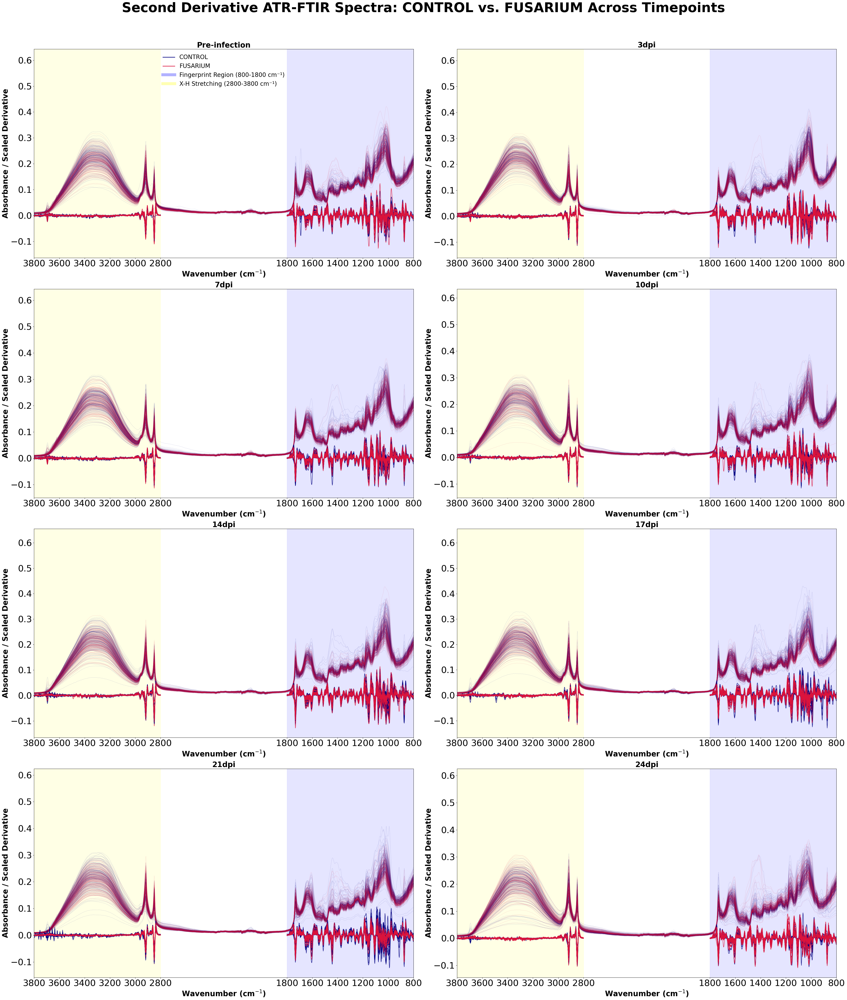

CPU times: total: 2min 1s
Wall time: 2min 2s


In [9]:
%%time
n_time_points = len(time_points_original)
n_cols = 2
n_rows = math.ceil(n_time_points / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20 * n_cols, 12 * n_rows))
axes = axes.flatten() if n_rows * n_cols > 1 else [axes]

for i, time_point in enumerate(time_points_original):
    ax = axes[i]
    time_data = df[df['timepoint'] == time_point]
    time_subset = data_with_deriv[data_with_deriv['timepoint'] == time_point]

    for sample_name, group in time_data.groupby('sample_name'):
        infection_status = group['infection_status'].iloc[0]
        ax.plot(group['wavenumber'], group['absorbance'],
                color=status_colors[infection_status], linewidth=0.5, alpha=0.2)

    ax.axvspan(*FINGERPRINT, color='blue', alpha=0.1)
    ax.axvspan(*STRETCHING, color='yellow', alpha=0.1)

    for sample_name, group in time_subset.groupby('sample_name'):
        infection_status = group['infection_status'].iloc[0]
        for x_min, x_max in (FINGERPRINT, STRETCHING):
            r = group[(group['wavenumber'] >= x_min) & (group['wavenumber'] <= x_max)].sort_values('wavenumber')
            ax.plot(r['wavenumber'], r['deriv_rescaled'],
                    color=status_colors[infection_status], linewidth=1.5, alpha=0.8)

    ax.invert_xaxis()
    ax.set_xlabel('Wavenumber (cm$^{-1}$)', fontsize=25, fontweight='bold')
    ax.set_ylabel('Absorbance / Scaled Derivative', fontsize=25, fontweight='bold')
    ax.set_title(timepoint_mapping[time_point], fontsize=25, fontweight='bold')
    ax.set_xticks(X_TICKS)
    ax.tick_params(axis='both', which='major', labelsize=30)
    ax.set_xlim(3800, 800)

    if i == 0:
        legend_elements = [
            *[Line2D([0], [0], color=color, lw=2, label=status) for status, color in status_colors.items()],
            Line2D([0], [0], color='blue', alpha=0.3, lw=10, label='Fingerprint Region (800-1800 cm⁻¹)'),
            Line2D([0], [0], color='yellow', alpha=0.3, lw=10, label='X-H Stretching (2800-3800 cm⁻¹)'),
        ]
        ax.legend(handles=legend_elements, fontsize=20, frameon=False, loc='upper center')

for j in range(n_time_points, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle('Second Derivative ATR-FTIR Spectra: CONTROL vs. FUSARIUM Across Timepoints',
             fontsize=45, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.savefig(os.path.join(OUTPUT_DIR, 'All_Timepoints_Full_Data.jpg'), dpi=600, bbox_inches='tight', format='jpeg')
plt.show()

## Overlay: median and range

The same comparison summarised as the median and the min–max band for each infection status, for raw absorbance and for the rescaled second derivative.

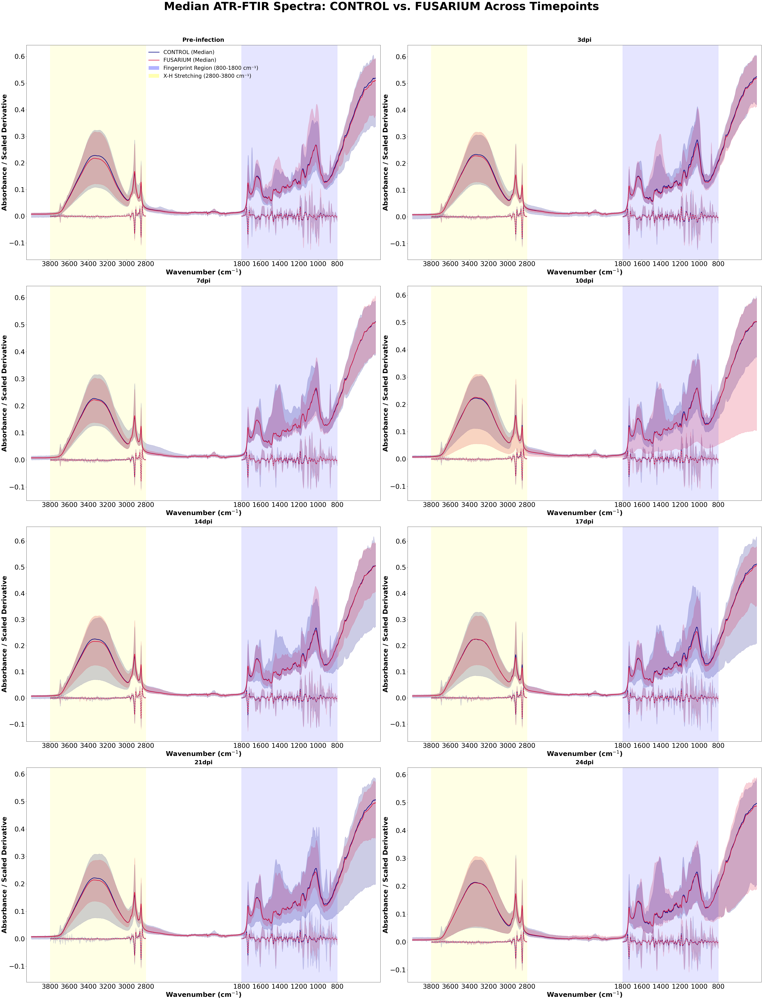

CPU times: total: 3min 35s
Wall time: 3min 42s


In [10]:
%%time
n_cols = 2
n_rows = math.ceil(n_time_points / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(24 * n_cols, 16 * n_rows))
axes = axes.flatten() if n_rows * n_cols > 1 else [axes]

for i, time_point in enumerate(time_points_original):
    ax = axes[i]
    time_data = df[df['timepoint'] == time_point]
    time_subset = data_with_deriv[data_with_deriv['timepoint'] == time_point]

    for infection_status in ['CONTROL', 'FUSARIUM']:
        status_data = time_data[time_data['infection_status'] == infection_status]
        if len(status_data) > 0:
            wavenumbers = sorted(status_data['wavenumber'].unique())
            medians, min_vals, max_vals = get_median_range(status_data, 'absorbance', wavenumbers)
            ax.fill_between(wavenumbers, min_vals, max_vals,
                            color=status_colors[infection_status], alpha=0.2, label='_nolegend_')
            ax.plot(wavenumbers, medians, color=status_colors[infection_status], linewidth=2.5,
                    label=f'{infection_status} (Raw)' if i == 0 else "")

    ax.axvspan(*FINGERPRINT, color='blue', alpha=0.1)
    ax.axvspan(*STRETCHING, color='yellow', alpha=0.1)

    for infection_status in ['CONTROL', 'FUSARIUM']:
        status_deriv = time_subset[time_subset['infection_status'] == infection_status]
        for x_min, x_max in (FINGERPRINT, STRETCHING):
            r = status_deriv[(status_deriv['wavenumber'] >= x_min) & (status_deriv['wavenumber'] <= x_max)]
            if len(r) > 0:
                wavenumbers = sorted(r['wavenumber'].unique())
                medians, min_vals, max_vals = get_median_range(r, 'deriv_rescaled', wavenumbers)
                ax.fill_between(wavenumbers, min_vals, max_vals,
                                color=status_colors[infection_status], alpha=0.15, label='_nolegend_')
                ax.plot(wavenumbers, medians, color=status_colors[infection_status],
                        linewidth=2.0, linestyle='--',
                        label=f'{infection_status} (2nd Deriv)' if (i == 0 and x_min == FINGERPRINT[0]) else "")

    ax.invert_xaxis()
    ax.set_xlabel('Wavenumber (cm$^{-1}$)', fontsize=30, fontweight='bold')
    ax.set_ylabel('Absorbance / Scaled Derivative', fontsize=30, fontweight='bold')
    ax.set_title(timepoint_mapping[time_point], fontsize=26, fontweight='bold', pad=15)
    ax.set_xticks(X_TICKS)
    ax.tick_params(axis='both', which='major', labelsize=30)
    ax.set_xlim(df['wavenumber'].max() + 50, df['wavenumber'].min() - 50)

    if i == 0:
        legend_elements = [
            Line2D([0], [0], color='#000080', lw=2.5, label='CONTROL (Median)'),
            Line2D([0], [0], color='#DC143C', lw=2.5, label='FUSARIUM (Median)'),
            Patch(facecolor='blue', alpha=0.3, label='Fingerprint Region (800-1800 cm⁻¹)'),
            Patch(facecolor='yellow', alpha=0.3, label='X-H Stretching (2800-3800 cm⁻¹)'),
        ]
        ax.legend(handles=legend_elements, fontsize=24, frameon=False,
                  loc='upper center', bbox_to_anchor=(0.5, 1.00))

for j in range(n_time_points, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle('Median ATR-FTIR Spectra: CONTROL vs. FUSARIUM Across Timepoints',
             fontsize=50, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.savefig(os.path.join(OUTPUT_DIR, 'All_Timepoints_Median.jpg'), dpi=600, bbox_inches='tight', format='jpeg')
plt.show()

## Single timepoint close-up (T5)

T5 (17 dpi) with the median and range of the raw and rescaled second-derivative spectra.

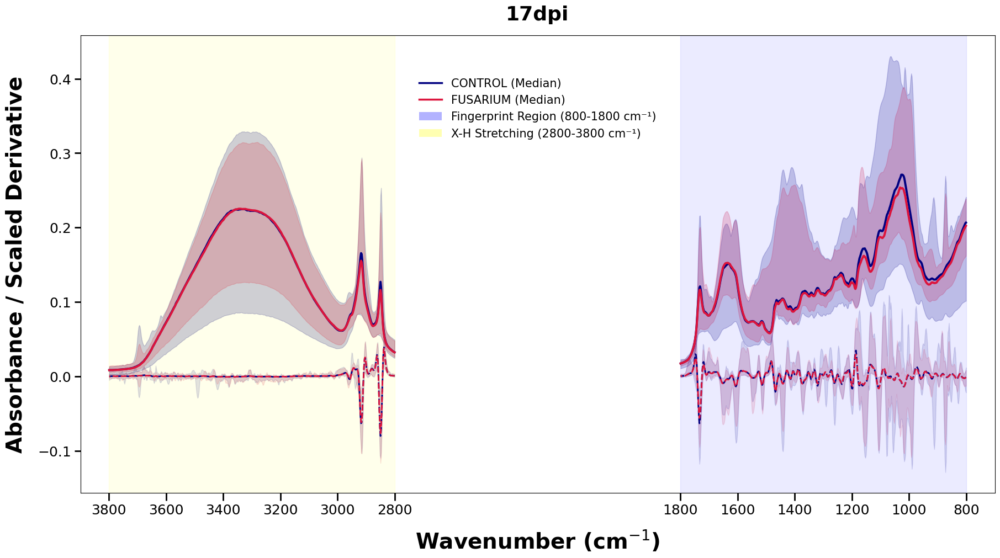

CPU times: total: 19.9 s
Wall time: 20.1 s


In [11]:
%%time
selected_timepoint = 'T5'
time_data = df[df['timepoint'] == selected_timepoint]
time_subset = data_with_deriv[data_with_deriv['timepoint'] == selected_timepoint]

fig, ax = plt.subplots(figsize=(18, 10), constrained_layout=True)


def plot_region(data_source, value_column, x_min, x_max, linestyle='-', linewidth=2.5, alpha_fill=0.2):
    for infection_status in ['CONTROL', 'FUSARIUM']:
        status_data = data_source[
            (data_source['infection_status'] == infection_status) &
            (data_source['wavenumber'] >= x_min) &
            (data_source['wavenumber'] <= x_max)
        ]
        if len(status_data) > 0:
            wavenumbers = sorted(status_data['wavenumber'].unique())
            medians, min_values, max_values = get_median_range(status_data, value_column, wavenumbers)
            ax.fill_between(wavenumbers, min_values, max_values,
                            color=status_colors[infection_status], alpha=alpha_fill)
            ax.plot(wavenumbers, medians, color=status_colors[infection_status],
                    linewidth=linewidth, linestyle=linestyle)


# raw first, second derivative on top
for x_min, x_max in (FINGERPRINT, STRETCHING):
    plot_region(time_data, 'absorbance', x_min, x_max, linestyle='-', linewidth=2.8, alpha_fill=0.20)
for x_min, x_max in (FINGERPRINT, STRETCHING):
    plot_region(time_subset, 'deriv_rescaled', x_min, x_max, linestyle='--', linewidth=2.0, alpha_fill=0.12)

ax.axvspan(*FINGERPRINT, color='blue', alpha=0.08)
ax.axvspan(*STRETCHING, color='yellow', alpha=0.08)

ax.invert_xaxis()
ax.set_xlim(3900, 700)
ax.set_xlabel('Wavenumber (cm$^{-1}$)', fontsize=28, fontweight='bold', labelpad=15)
ax.set_ylabel('Absorbance / Scaled Derivative', fontsize=28, fontweight='bold', labelpad=15)
ax.set_title(timepoint_mapping[selected_timepoint], fontsize=26, fontweight='bold', pad=20)

ax.set_xticks([3800, 3600, 3400, 3200, 3000, 2800, 1800, 1600, 1400, 1200, 1000, 800])
ax.tick_params(axis='x', direction='out', length=10, width=2, labelsize=18, bottom=True)
ax.tick_params(axis='y', direction='out', length=8, width=2, labelsize=18, left=True)

legend_elements = [
    Line2D([0], [0], color='#000080', lw=2.5, label='CONTROL (Median)'),
    Line2D([0], [0], color='#DC143C', lw=2.5, label='FUSARIUM (Median)'),
    Patch(facecolor='blue', alpha=0.3, label='Fingerprint Region (800-1800 cm⁻¹)'),
    Patch(facecolor='yellow', alpha=0.3, label='X-H Stretching (2800-3800 cm⁻¹)'),
]
ax.legend(handles=legend_elements, fontsize=15, frameon=False, loc='upper center', bbox_to_anchor=(0.5, 0.93))

plt.savefig(os.path.join(OUTPUT_DIR, 'T5_Timepoint_Median.jpg'), dpi=600, bbox_inches='tight', facecolor='white')
plt.show()

## PCA helper functions

`plot_region_pca` pivots a region subset to one row per sample, standardises each wavenumber with `StandardScaler`, runs PCA and plots PC1 against PC2 for every group in a grid (timepoints by default). Colour is infection status, marker is trial, and each infection status gets a 95% confidence ellipse (`confidence_ellipse`). For every panel it also appends one Bhattacharyya result and one Puri–Sen result to the lists it receives.

`run_bhattacharyya_overlap` fits a bivariate Gaussian to the PC1/PC2 scores of CONTROL and FUSARIUM and returns the Bhattacharyya coefficient (BC) with a percentile bootstrap 95% interval from `N_BOOTSTRAP` resamples. BC is 1 when the two distributions are identical and goes towards 0 as they separate. It describes effect size and is not a test. A result is flagged `substantial_overlap` when the lower end of the interval is above `OVERLAP_THRESHOLD` (0.5).

`run_multivariate_kruskal_wallis` is the Puri–Sen (1971) multivariate extension of Kruskal-Wallis, applied jointly to PC1 and PC2. Ranks are computed for each PC across all samples in the panel, and each group's mean rank vector is compared with the overall one through the inverse of the rank covariance matrix. The statistic L follows a chi-square distribution with p(k − 1) degrees of freedom, where p = 2 PCs and k = 2 groups.

`apply_bonferroni_correction` multiplies each p-value by the number of tests in the same region and spectrum type, so every combination is corrected on its own.

In [12]:
%%time
trial_markers = {'E1': 'o', 'E2': 's', 'E3': '^'}


def confidence_ellipse(x, y, ax, n_std=1.96, facecolor='none', **kwargs):
    if len(x) < 2:
        return
    cov = np.cov(x, y)
    pearson = cov[0, 1] / np.sqrt(cov[0, 0] * cov[1, 1])
    ellipse = Ellipse((0, 0), width=np.sqrt(1 + pearson) * 2, height=np.sqrt(1 - pearson) * 2,
                      facecolor=facecolor, **kwargs)
    transf = (transforms.Affine2D()
              .rotate_deg(45)
              .scale(np.sqrt(cov[0, 0]) * n_std, np.sqrt(cov[1, 1]) * n_std)
              .translate(np.mean(x), np.mean(y)))
    ellipse.set_transform(transf + ax.transData)
    return ax.add_patch(ellipse)


def bhattacharyya_coefficient(x_a, x_b):
    mu_a, mu_b = x_a.mean(axis=0), x_b.mean(axis=0)
    cov_a = np.cov(x_a, rowvar=False)
    cov_b = np.cov(x_b, rowvar=False)
    cov_pooled = (cov_a + cov_b) / 2

    try:
        cov_pooled_inv = np.linalg.inv(cov_pooled)
    except np.linalg.LinAlgError:
        return np.nan

    diff = mu_a - mu_b
    mean_term = 0.125 * (diff @ cov_pooled_inv @ diff)

    det_pooled = np.linalg.det(cov_pooled)
    det_a = np.linalg.det(cov_a)
    det_b = np.linalg.det(cov_b)
    if det_pooled <= 0 or det_a <= 0 or det_b <= 0:
        return np.nan

    cov_term = 0.5 * np.log(det_pooled / np.sqrt(det_a * det_b))
    return np.exp(-(mean_term + cov_term))


def run_bhattacharyya_overlap(pc1_scores, pc2_scores, labels, n_bootstrap=N_BOOTSTRAP,
                              random_state=RANDOM_STATE, ci=95):
    labels = np.asarray(labels)
    groups = np.unique(labels)
    n_total = len(labels)

    if len(groups) != 2 or n_total < 3:
        return np.nan, np.nan, np.nan, n_total

    idx_a = labels == groups[0]
    idx_b = labels == groups[1]
    n_a, n_b = idx_a.sum(), idx_b.sum()

    if n_a < 5 or n_b < 5:
        return np.nan, np.nan, np.nan, n_total

    x_a = np.column_stack([pc1_scores[idx_a], pc2_scores[idx_a]])
    x_b = np.column_stack([pc1_scores[idx_b], pc2_scores[idx_b]])

    obs_bc = bhattacharyya_coefficient(x_a, x_b)

    rng = np.random.default_rng(random_state)
    boot_bc = np.empty(n_bootstrap)
    for b in range(n_bootstrap):
        sample_a = x_a[rng.integers(0, n_a, n_a)]
        sample_b = x_b[rng.integers(0, n_b, n_b)]
        boot_bc[b] = bhattacharyya_coefficient(sample_a, sample_b)

    boot_bc = boot_bc[~np.isnan(boot_bc)]
    if len(boot_bc) < 10:
        return obs_bc, np.nan, np.nan, n_total

    tail = (100 - ci) / 2
    bc_lo, bc_hi = np.percentile(boot_bc, [tail, 100 - tail])
    return obs_bc, bc_lo, bc_hi, n_total


def run_multivariate_kruskal_wallis(pca_df, pc_cols=('PC1', 'PC2')):
    labels = pca_df['infection_status'].to_numpy()
    groups = np.unique(labels)
    data = pca_df[list(pc_cols)].to_numpy()
    n_total, n_pcs = data.shape
    n_groups = len(groups)

    if n_total < 3 or n_groups < 2:
        return np.nan, np.nan, n_total

    ranks = np.column_stack([rankdata(data[:, j]) for j in range(n_pcs)])
    overall_mean_rank = ranks.mean(axis=0)

    centered = ranks - overall_mean_rank
    rank_cov = (centered.T @ centered) / (n_total - 1)

    try:
        rank_cov_inv = np.linalg.inv(rank_cov)
    except np.linalg.LinAlgError:
        return np.nan, np.nan, n_total

    stat = 0.0
    for g in groups:
        in_group = labels == g
        n_g = in_group.sum()
        if n_g < 2:
            continue
        diff = (ranks[in_group].mean(axis=0) - overall_mean_rank).reshape(-1, 1)
        stat += n_g * (diff.T @ rank_cov_inv @ diff).item()

    dof = n_pcs * (n_groups - 1)
    p_value = float(chi2.sf(stat, dof))
    return stat, p_value, n_total


def apply_bonferroni_correction(kw_df, p_col, alpha=ALPHA):
    corrected = kw_df.copy()
    corrected['n_tests'] = corrected.groupby(['region', 'spectrum'])[p_col].transform('count')
    corrected['p_bonferroni'] = (corrected[p_col] * corrected['n_tests']).clip(upper=1.0)
    corrected['significant_bonferroni'] = corrected['p_bonferroni'] < alpha
    return corrected


def plot_region_pca(region_subset, value_col, region_name, wavenumber_range_str, spectrum_label, output_filename,
                    overlap_results, kw_results, group_col='timepoint', group_order=None, group_labels=None):
    groups = group_order if group_order is not None else sorted(region_subset[group_col].unique())
    n_cols = 2
    n_rows = math.ceil(len(groups) / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(10 * n_cols, 8 * n_rows))
    axes = axes.flatten() if n_rows * n_cols > 1 else [axes]

    for i, group_value in enumerate(groups):
        group_data = region_subset[region_subset[group_col] == group_value]
        spectra_wide = group_data.pivot(index='sample_name', columns='wavenumber', values=value_col).fillna(0)
        metadata = group_data[['sample_name', 'infection_status', 'trial']].drop_duplicates().set_index('sample_name')

        scaled_data = StandardScaler().fit_transform(spectra_wide)
        pca = PCA()
        pca_result = pca.fit_transform(scaled_data)

        pca_df = pd.DataFrame(pca_result, columns=[f'PC{j + 1}' for j in range(pca_result.shape[1])],
                              index=spectra_wide.index)
        pca_df['infection_status'] = metadata['infection_status']
        pca_df['trial'] = metadata['trial']
        var_explained = pca.explained_variance_ratio_ * 100

        sns.set(style="white")
        ax = axes[i]

        for status, status_color in status_colors.items():
            for trial, marker in trial_markers.items():
                points = pca_df[(pca_df['infection_status'] == status) & (pca_df['trial'] == trial)]
                if len(points) > 0:
                    ax.scatter(points['PC1'], points['PC2'], c=status_color, s=100, alpha=0.8,
                               marker=marker, edgecolor='w', linewidth=0.5, label=f'{status} ({trial})')

        for status, color in status_colors.items():
            points = pca_df[pca_df['infection_status'] == status]
            if len(points) > 1:
                confidence_ellipse(points['PC1'], points['PC2'], ax, n_std=1.96,
                                   edgecolor=color, linestyle='--', linewidth=1.5, alpha=0.7, facecolor='none')

        group_title = group_labels.get(group_value, group_value) if group_labels else group_value

        ax.set_title(group_title, fontsize=16, fontweight='bold', pad=15)
        ax.set_xlabel(f'PC1 ({var_explained[0]:.1f}%)', fontsize=14, fontweight='bold')
        ax.set_ylabel(f'PC2 ({var_explained[1]:.1f}%)', fontsize=14, fontweight='bold')
        ax.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.3)

        if i == 0:
            handles, labels = ax.get_legend_handles_labels()
            by_label = dict(zip(labels, handles))
            ax.legend(by_label.values(), by_label.keys(), title='Infection Status (Trial)',
                      title_fontsize='12', fontsize='10', frameon=True,
                      bbox_to_anchor=(1.05, 1), loc='upper left')

        obs_bc, bc_ci_low, bc_ci_high, n_bc = run_bhattacharyya_overlap(
            pca_df['PC1'].to_numpy(), pca_df['PC2'].to_numpy(), pca_df['infection_status'].to_numpy())
        overlap_results.append({
            'region': region_name,
            'spectrum': spectrum_label,
            'group': group_title,
            'n_samples': n_bc,
            'bhattacharyya_coefficient': obs_bc,
            'bhattacharyya_coefficient_CI_low': bc_ci_low,
            'bhattacharyya_coefficient_CI_high': bc_ci_high,
            'substantial_overlap_(CI_low>threshold)': (bc_ci_low > OVERLAP_THRESHOLD) if not np.isnan(bc_ci_low) else np.nan,
        })

        puri_sen_L, puri_sen_p, n_ps = run_multivariate_kruskal_wallis(pca_df)
        kw_results.append({
            'region': region_name,
            'spectrum': spectrum_label,
            'group': group_title,
            'n_samples': n_ps,
            'puri_sen_L_statistic': puri_sen_L,
            'puri_sen_p_value': puri_sen_p,
        })

    for j in range(len(groups), len(axes)):
        fig.delaxes(axes[j])

    fig.suptitle(f'PCA of {spectrum_label} FTIR Spectra: CONTROL vs. FUSARIUM Across Timepoints and Trials\n'
                 f'{region_name} Region: {wavenumber_range_str} cm$^{{-1}}$',
                 fontsize=35, fontweight='bold', y=0.98)
    plt.tight_layout(rect=[0, 0, 1, 0.96])

    plt.savefig(os.path.join(OUTPUT_DIR, output_filename), dpi=600, bbox_inches='tight', format='jpeg')
    plt.show()

CPU times: total: 0 ns
Wall time: 590 μs


## PCA per timepoint

`plot_region_pca` is called for each region (Combined, Fingerprint, Stretching) and each spectrum type (raw, second derivative). That gives six figures with one panel per timepoint, or 8 timepoints × 3 regions × 2 spectrum types = 48 panels.

The Bhattacharyya results are saved to `Bhattacharyya_Overlap_Results_Per_Timepoint.csv`. The Puri–Sen results, Bonferroni-corrected across the 8 timepoints within each region and spectrum type, are saved to `KruskalWallis_Results_Per_Timepoint.csv`.

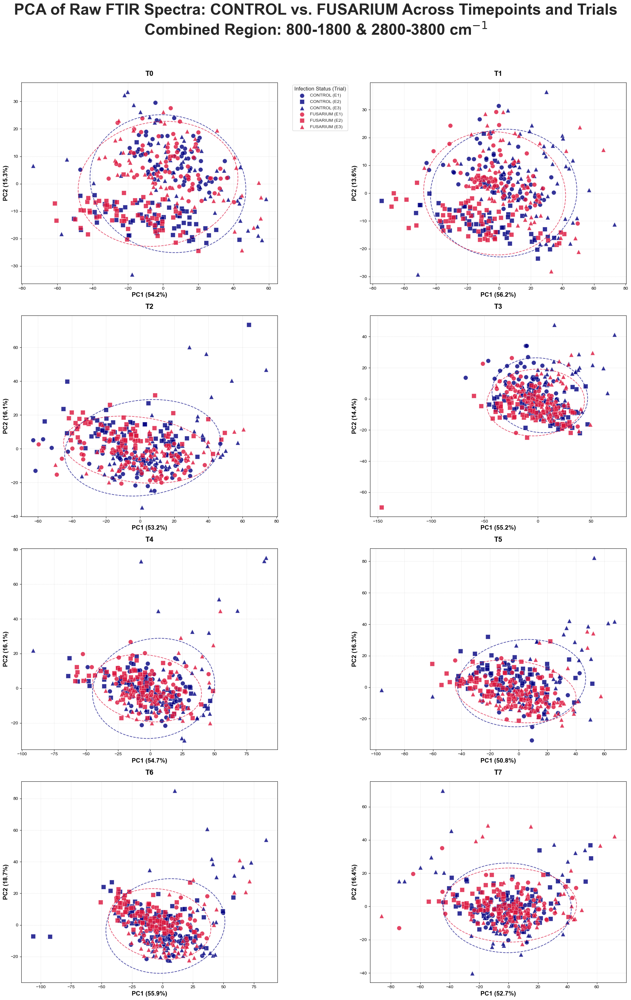

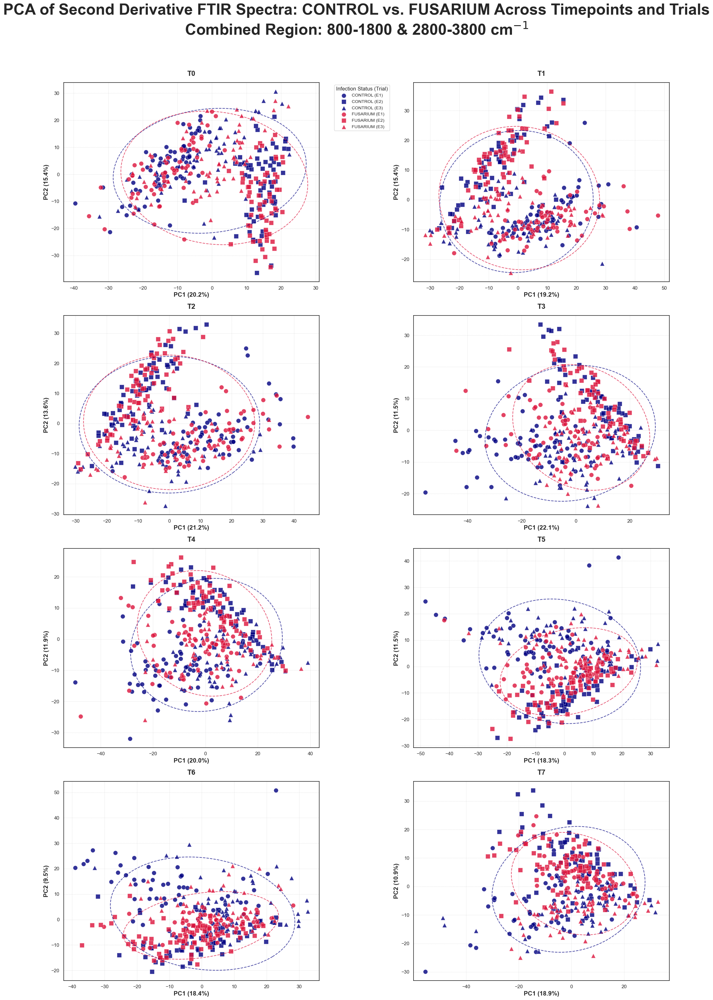

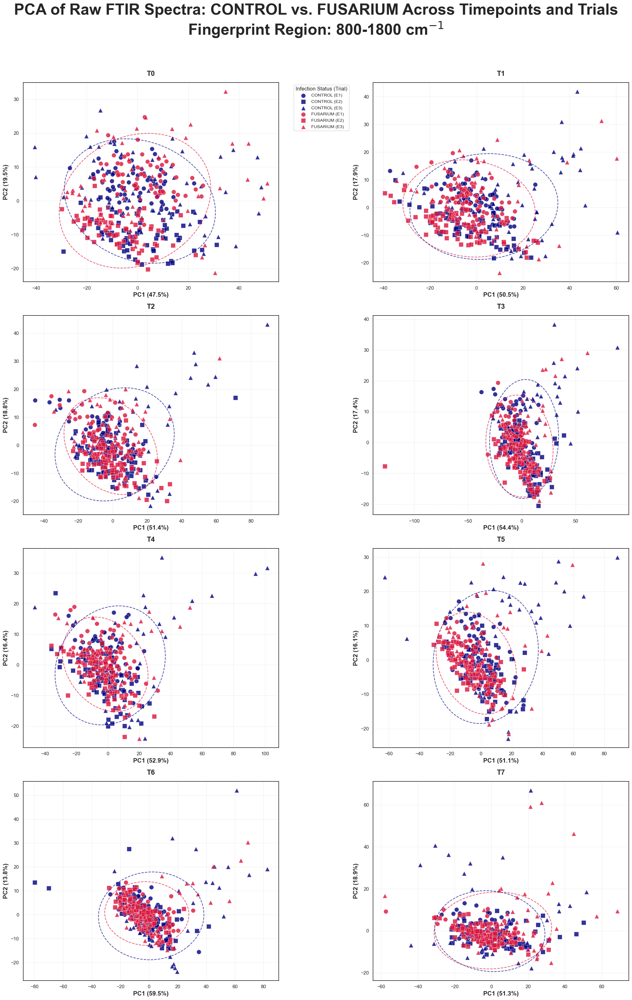

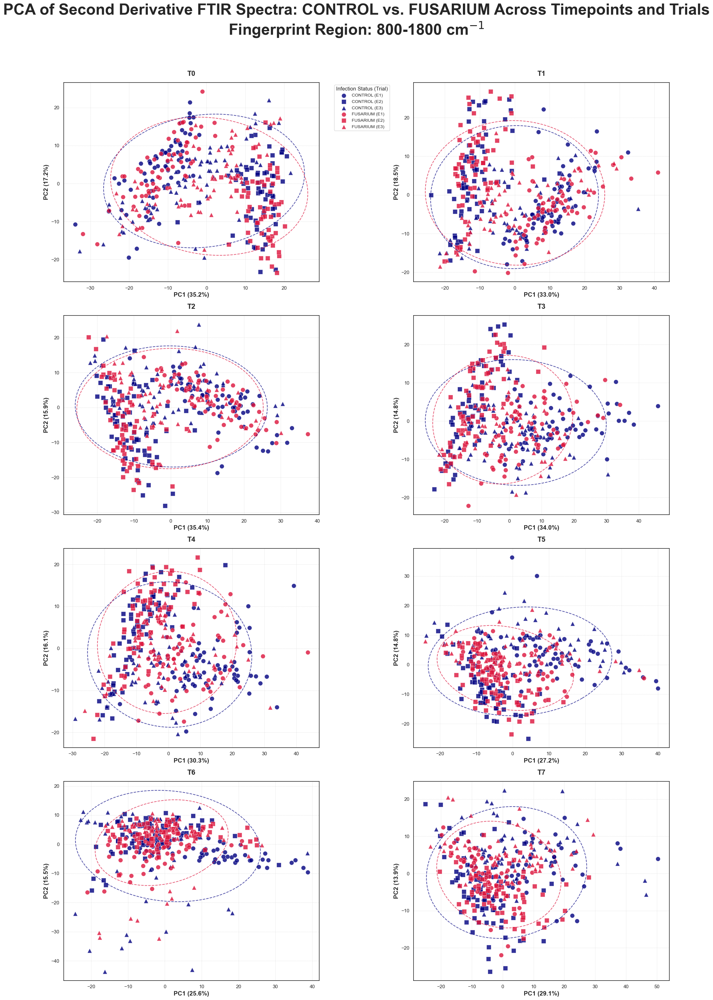

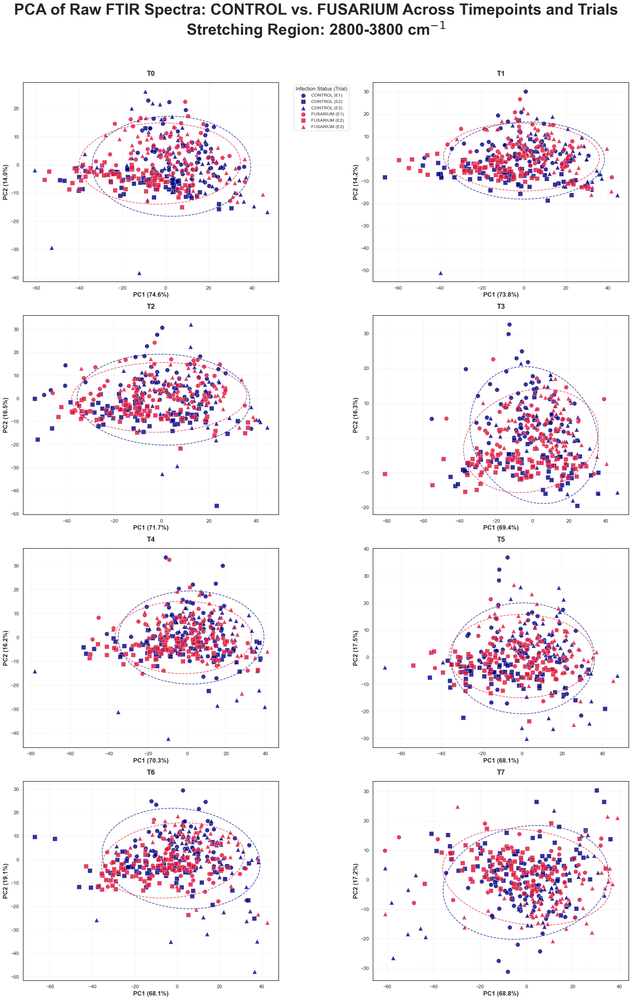

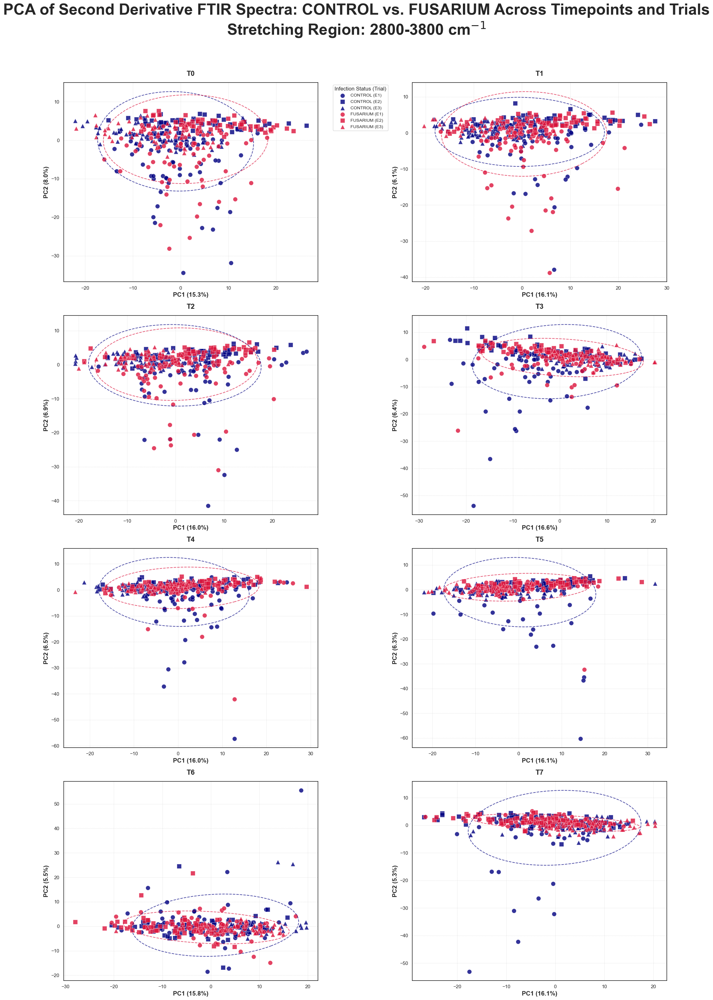

Bhattacharyya overlap, per-timepoint results saved to:
C:/Users/MCL/Desktop/ML_ATR_FTIR_Spectra_Ppinaster\Outputs\Plots\1_PCA_Combined_Regions_Raw_2Derivative_Per_Timepoint\Bhattacharyya_Overlap_Results_Per_Timepoint.csv
Median BC: 0.970. Substantial overlap (CI low > 0.5): 48 / 48

Puri-Sen test, per-timepoint results saved to:
C:/Users/MCL/Desktop/ML_ATR_FTIR_Spectra_Ppinaster\Outputs\Plots\1_PCA_Combined_Regions_Raw_2Derivative_Per_Timepoint\KruskalWallis_Results_Per_Timepoint.csv
Significant after Bonferroni (p < 0.05): 13 / 48
CPU times: total: 2min 39s
Wall time: 2min 8s


,region,spectrum,group,n_samples,bhattacharyya_coefficient,bhattacharyya_coefficient_CI_low,bhattacharyya_coefficient_CI_high,substantial_overlap_(CI_low>threshold)
0,Combined,Raw,T0,380,0.985857,0.955019,0.994897,True
1,Combined,Raw,T1,382,0.991176,0.965615,0.995988,True
2,Combined,Raw,T2,382,0.949585,0.887987,0.986632,True
3,Combined,Raw,T3,382,0.970605,0.914761,0.983121,True
4,Combined,Raw,T4,382,0.944986,0.853227,0.988585,True
5,Combined,Raw,T5,382,0.935007,0.845386,0.978217,True
6,Combined,Raw,T6,382,0.961095,0.889229,0.987811,True
7,Combined,Raw,T7,382,0.987742,0.942350,0.993969,True
8,Combined,Second Derivative,T0,380,0.986463,0.953672,0.996675,True
9,Combined,Second Derivative,T1,382,0.996932,0.975671,0.998333,True


In [13]:
%%time
REGION_RANGE_LABELS = [
    ('Combined', '800-1800 & 2800-3800'),
    ('Fingerprint', '800-1800'),
    ('Stretching', '2800-3800'),
]
SPECTRUM_TYPES = [
    ('absorbance_raw', 'Raw', 'Raw'),
    ('second_derivative_raw', 'Second Derivative', '2Deriv'),
]


def build_pca_configs(file_prefix):
    subsets = {
        'Combined': combined_subset,
        'Fingerprint': fingerprint_subset,
        'Stretching': stretching_subset,
    }
    configs = []
    for region_name, range_label in REGION_RANGE_LABELS:
        for value_col, spectrum_label, file_suffix in SPECTRUM_TYPES:
            filename = f'{file_prefix}_{region_name}_PCA_{file_suffix}.jpg'
            configs.append((subsets[region_name], value_col, region_name, range_label, spectrum_label, filename))
    return configs


def save_and_report(overlap_results, kw_results, label, overlap_csv, kw_csv):
    overlap_df = pd.DataFrame(overlap_results)
    overlap_path = os.path.join(OUTPUT_DIR, overlap_csv)
    overlap_df.to_csv(overlap_path, index=False)

    kw_df = apply_bonferroni_correction(pd.DataFrame(kw_results), 'puri_sen_p_value')
    kw_path = os.path.join(OUTPUT_DIR, kw_csv)
    kw_df.to_csv(kw_path, index=False)

    n_overlap = overlap_df['substantial_overlap_(CI_low>threshold)'].sum()
    print(f"Bhattacharyya overlap, {label} results saved to:\n{overlap_path}")
    print(f"Median BC: {overlap_df['bhattacharyya_coefficient'].median():.3f}. "
          f"Substantial overlap (CI low > {OVERLAP_THRESHOLD}): {n_overlap:.0f} / {len(overlap_df)}")
    print()
    print(f"Puri-Sen test, {label} results saved to:\n{kw_path}")
    print(f"Significant after Bonferroni (p < {ALPHA}): "
          f"{kw_df['significant_bonferroni'].sum():.0f} / {len(kw_df)}")
    return overlap_df, kw_df


overlap_results = []
kw_results = []

for region_subset, value_col, region_name, range_label, spectrum_label, filename in build_pca_configs('All_Timepoints'):
    plot_region_pca(region_subset, value_col, region_name, range_label, spectrum_label, filename,
                    overlap_results, kw_results)

overlap_df, kw_df = save_and_report(
    overlap_results, kw_results, 'per-timepoint',
    'Bhattacharyya_Overlap_Results_Per_Timepoint.csv',
    'KruskalWallis_Results_Per_Timepoint.csv')

overlap_df

## PCA on grouped timepoints

The same analysis with timepoints pooled into three groups: T0 (pre-infection), T1–T5 and T6–T7. The grouping goes in a `group_stage` column. Each figure has three panels, and the Bonferroni correction is applied across the 3 groups within each region and spectrum type.

Results are saved to `Bhattacharyya_Overlap_Results_Grouped_Timepoints.csv` and `KruskalWallis_Results_Grouped_Timepoints.csv`.

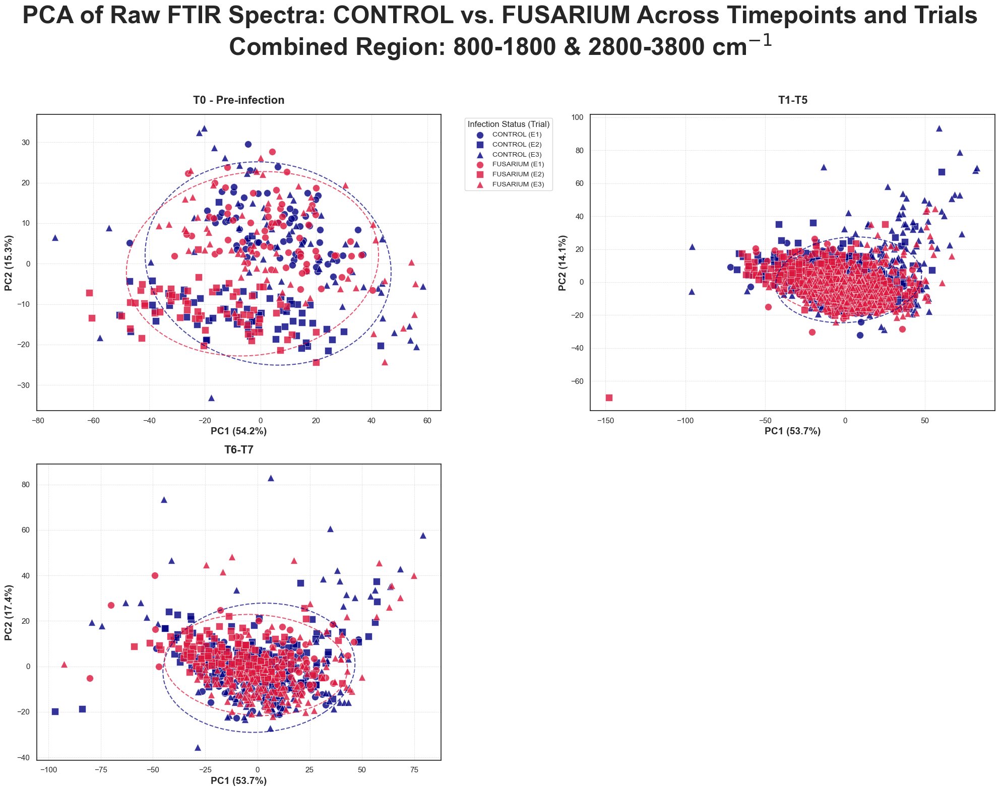

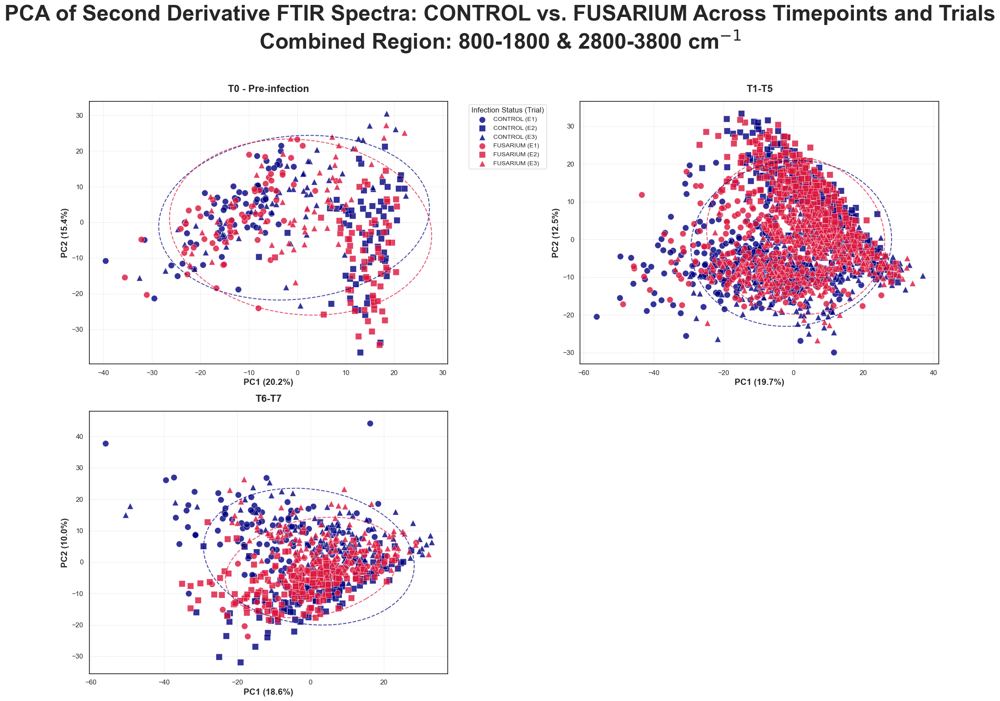

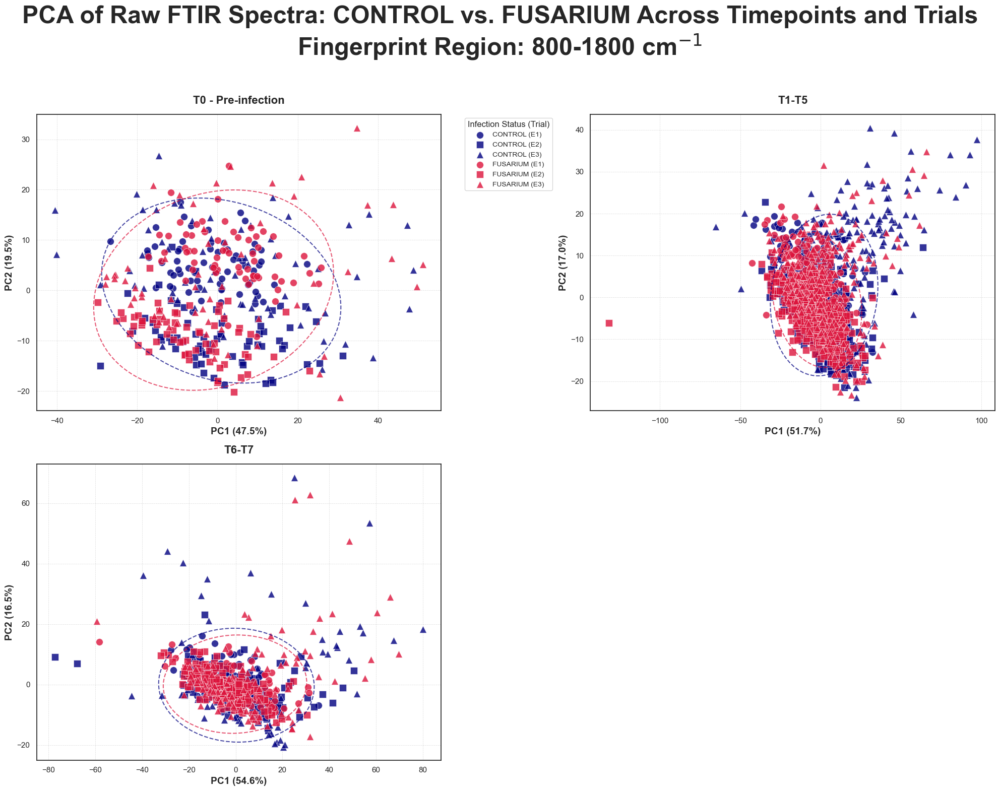

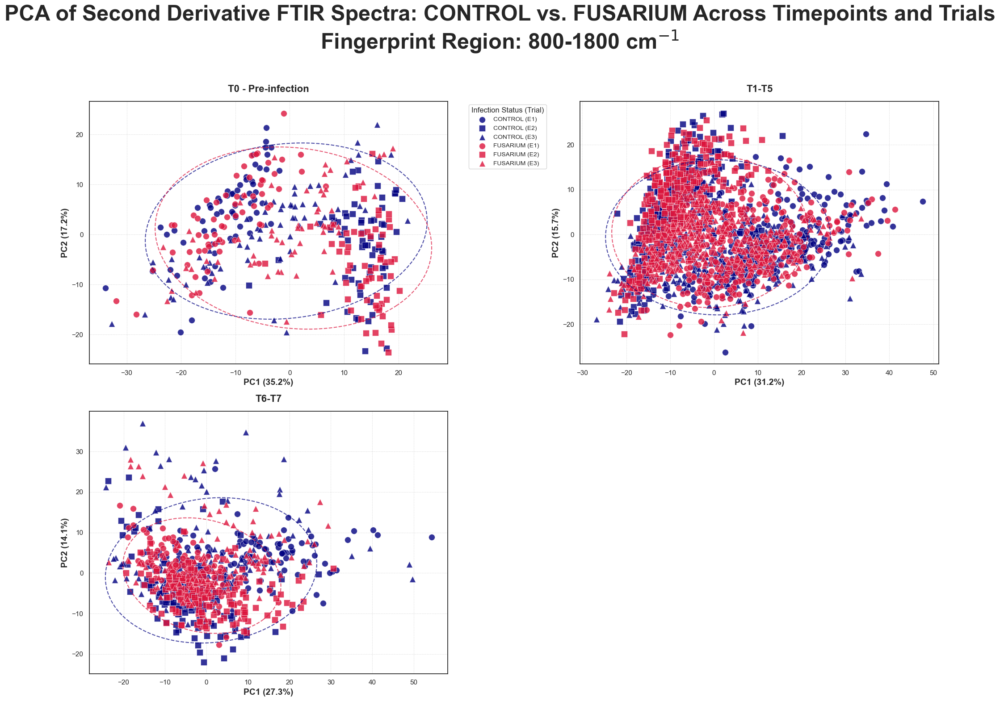

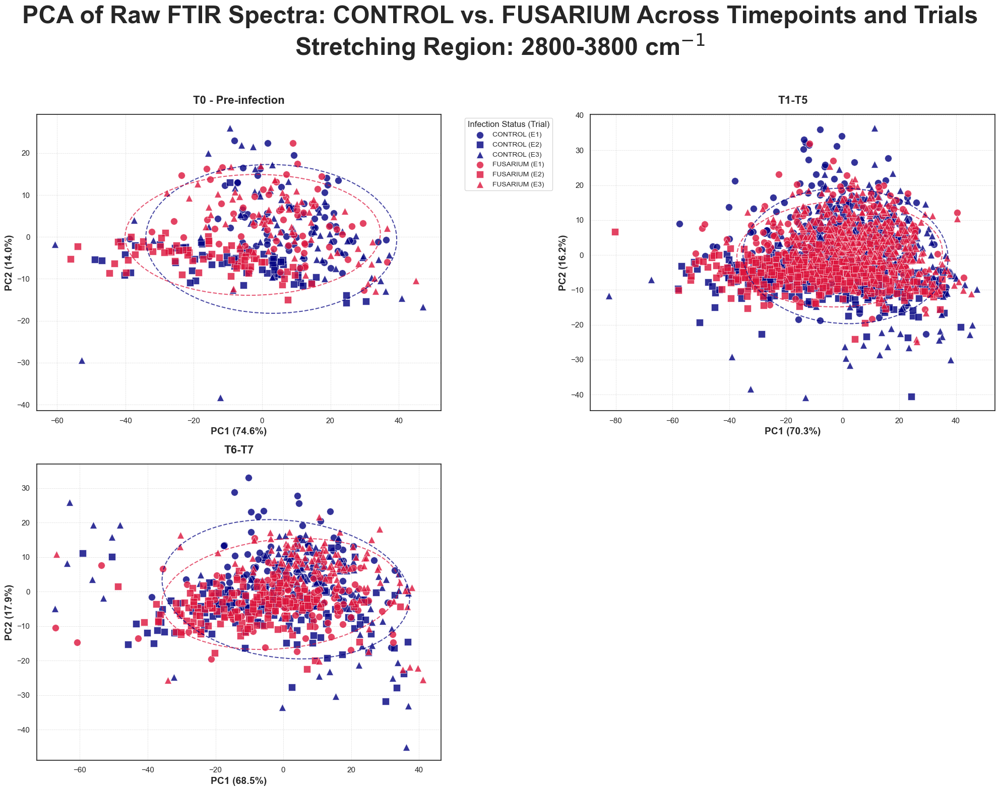

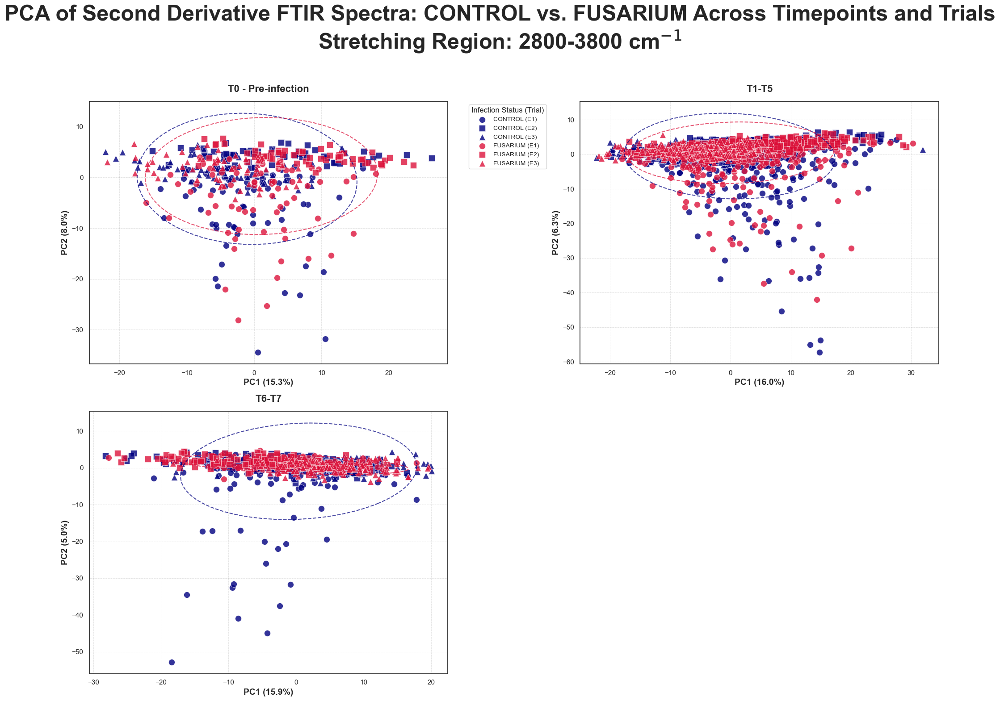

Bhattacharyya overlap, grouped-timepoint results saved to:
C:/Users/MCL/Desktop/ML_ATR_FTIR_Spectra_Ppinaster\Outputs\Plots\1_PCA_Combined_Regions_Raw_2Derivative_Per_Timepoint\Bhattacharyya_Overlap_Results_Grouped_Timepoints.csv
Median BC: 0.981. Substantial overlap (CI low > 0.5): 18 / 18

Puri-Sen test, grouped-timepoint results saved to:
C:/Users/MCL/Desktop/ML_ATR_FTIR_Spectra_Ppinaster\Outputs\Plots\1_PCA_Combined_Regions_Raw_2Derivative_Per_Timepoint\KruskalWallis_Results_Grouped_Timepoints.csv
Significant after Bonferroni (p < 0.05): 9 / 18
CPU times: total: 1min 29s
Wall time: 1min 9s


,region,spectrum,group,n_samples,bhattacharyya_coefficient,bhattacharyya_coefficient_CI_low,bhattacharyya_coefficient_CI_high,substantial_overlap_(CI_low>threshold)
0,Combined,Raw,T0 - Pre-infection,380,0.985857,0.955019,0.994897,True
1,Combined,Raw,T1-T5,1910,0.954322,0.916077,0.979592,True
2,Combined,Raw,T6-T7,764,0.980597,0.941426,0.992697,True
3,Combined,Second Derivative,T0 - Pre-infection,380,0.986463,0.953672,0.996675,True
4,Combined,Second Derivative,T1-T5,1910,0.988310,0.977810,0.994017,True
5,Combined,Second Derivative,T6-T7,764,0.935306,0.897606,0.962325,True
6,Fingerprint,Raw,T0 - Pre-infection,380,0.980496,0.948616,0.990501,True
7,Fingerprint,Raw,T1-T5,1910,0.961127,0.925868,0.981891,True
8,Fingerprint,Raw,T6-T7,764,0.992167,0.940623,0.997196,True
9,Fingerprint,Second Derivative,T0 - Pre-infection,380,0.989448,0.960414,0.997261,True


In [14]:
%%time
GROUP_ORDER = ['T0', 'T1_T5', 'T6_T7']
GROUP_LABELS = {'T0': 'T0 - Pre-infection', 'T1_T5': 'T1-T5', 'T6_T7': 'T6-T7'}


def assign_group_stage(timepoint):
    if timepoint == 'T0':
        return 'T0'
    elif timepoint in ['T1', 'T2', 'T3', 'T4', 'T5']:
        return 'T1_T5'
    else:
        return 'T6_T7'


for subset in (combined_subset, fingerprint_subset, stretching_subset):
    subset['group_stage'] = subset['timepoint'].apply(assign_group_stage)

overlap_results_grouped = []
kw_results_grouped = []

for region_subset, value_col, region_name, range_label, spectrum_label, filename in build_pca_configs('Grouped_Timepoints'):
    plot_region_pca(region_subset, value_col, region_name, range_label, spectrum_label, filename,
                    overlap_results_grouped, kw_results_grouped,
                    group_col='group_stage', group_order=GROUP_ORDER, group_labels=GROUP_LABELS)

overlap_grouped_df, kw_grouped_df = save_and_report(
    overlap_results_grouped, kw_results_grouped, 'grouped-timepoint',
    'Bhattacharyya_Overlap_Results_Grouped_Timepoints.csv',
    'KruskalWallis_Results_Grouped_Timepoints.csv')

overlap_grouped_df